In [1]:
import sklearn
import torch
import matplotlib
import pandas as pd
import numpy as np
import pickle
import torch.nn as nn
import random
import matplotlib.pyplot as plt
from collections import Counter
device="cpu"

In [2]:
df=pd.read_csv("./TrainData/single_drain_readings.csv")
df.info()
df['timestamp'] = pd.to_datetime(df['timestamp'])

df = df.sort_values('timestamp').reset_index(drop=True)

df['hour'] = df['timestamp'].dt.hour
df['month_num'] = df['timestamp'].dt.month

# df['hour_sin'] = np.sin(2 * np.pi * df['hour']/23.0)

# df['hour_cos'] = np.cos(2 * np.pi * df['hour']/23.0)

# df['month_sin'] = np.sin(2 * np.pi * df['month_num']/12.0)
# df['month_cos'] = np.cos(2 * np.pi * df['month_num']/12.0)

df = pd.get_dummies(df, columns=['season', 'weather_state'])

features = [
    'temp_c', 'rh_pct', 'rain_mm', 'rain_intensity_mmph', 'demand_index', 'inflow_lps', 'smoothed_flow_lps', 'level_cm',
    'hour_sin', 'hour_cos', 'month_sin', 'month_cos','season_winter', 'season_pre_monsoon', 'season_monsoon', 'season_post_monsoon',
    'weather_state_clear', 'weather_state_cloudy', 'weather_state_drizzle', 'weather_state_light_rain', 'weather_state_moderate_rain', 'weather_state_heavy_rain'
]

for col in features:
    if not col in df.columns:
        df[col]=0
        
data=df[features]

splitrat=0.8
Train=data[:int(splitrat*len(data))]
Val=data[int(splitrat*len(data)):]

scalerAlg=sklearn.preprocessing.MinMaxScaler()


Train=scalerAlg.fit_transform(Train)

Val=scalerAlg.transform(Val)

with open('scaler.pkl', 'wb') as f:
    pickle.dump(scalerAlg, f)
    
# So the test set ill gen later by Manipulating some values and stuff ig

print(len(Train))
print(len(Val))

<class 'pandas.DataFrame'>
RangeIndex: 43800 entries, 0 to 43799
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   timestamp            43800 non-null  str    
 1   month                43800 non-null  str    
 2   season               43800 non-null  str    
 3   temp_c               43800 non-null  float64
 4   rh_pct               43800 non-null  float64
 5   weather_state        43800 non-null  str    
 6   F_temperature        43800 non-null  float64
 7   F_humidity           43800 non-null  float64
 8   F_season             43800 non-null  float64
 9   F_weather            43800 non-null  float64
 10  E                    43800 non-null  float64
 11  rain_mm              43800 non-null  float64
 12  rain_intensity_mmph  43800 non-null  float64
 13  demand_index         43800 non-null  float64
 14  inflow_lps           43800 non-null  float64
 15  smoothed_flow_lps    43800 non-null  float64
 1

In [3]:
def PackintoWindows(Ds,n=24):
    data=[]
    for i in range(len(Ds)-n):
        data.append(Ds[i:i+n])
    return torch.tensor(np.array(data),dtype=torch.float32)

def createDF(Ds,label="level_cm"):
    X=Ds.drop(label)
    y=Ds[label]
    return (X,y)

In [4]:
X_train = PackintoWindows(Train, n=24)
X_val = PackintoWindows(Val, n=24)

seq_len = X_train.shape[1]
n_features = X_train.shape[2]
X_train=torch.utils.data.TensorDataset(X_train,X_train)
X_val=torch.utils.data.TensorDataset(X_val,X_val)
batch_size=16
X_train=torch.utils.data.DataLoader(X_train,batch_size=batch_size,shuffle=True)

X_val=torch.utils.data.DataLoader(X_val,batch_size=batch_size,shuffle=False)

In [5]:
class Enc(nn.Module):
    def __init__(self, inF, emb=64, nLstm=2):
        super().__init__()
        self.l1 = nn.LSTM(input_size=inF,hidden_size=2*emb,num_layers=1,batch_first=True)
        self.l2 = nn.LSTM(input_size=2*emb,hidden_size=emb,num_layers=1,batch_first=True)

    def forward(self, x):
        x, _ = self.l1(x)
        x, (hidden_n, _) = self.l2(x)
        return hidden_n.transpose(0, 1)

class Dec(nn.Module):
    def __init__(self, seq_len, emb, outF, nLstm=2):
        super().__init__()
        self.seq_len = seq_len
        self.l1 = nn.LSTM(input_size=emb,hidden_size=emb,num_layers=1,batch_first=True)
        self.l2 = nn.LSTM(input_size=emb,hidden_size=emb*2,num_layers=1,batch_first=True)
        
        self.output_layer = nn.Linear(emb*2, outF)

    def forward(self, x):
        x = x.repeat(1, self.seq_len, 1)
        x, _ = self.l1(x)
        x, _ = self.l2(x)
        return self.output_layer(x)

class lsmtAE(nn.Module):
    def __init__(self, seq_len, n_features, embedding_dim=64, nLstmENC=2, nLstmDec=2):
        super().__init__()
        self.encoder = Enc(n_features, embedding_dim).to(device)
        self.decoder = Dec(seq_len, embedding_dim, n_features).to(device)

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x
    

In [6]:
def val(model, lossF, valD, giveLoss=False):
    model.eval()
    with torch.inference_mode():
        Tloss=0
        for X,y in tqdm(valD,desc="Validating .... ",leave=False):
            X,y=X.to(device),y.to(device)
            preds=model(X)
            loss=lossF(preds,y)
            Tloss+=loss.item()*X.size(0)
    return Tloss/len(valD.dataset)
def testF(model, testD, giveLossL=False):
    model.eval()
    with torch.inference_mode():
        sequence_errors = []
        for X,y in tqdm(testD,desc="Validating .... ",leave=False):
            X,y=X.to(device),y.to(device)
            preds=model(X)
            seq_loss = torch.mean(torch.abs(preds - y), dim=(1, 2))
            sequence_errors.extend(seq_loss.cpu().numpy())
        sequence_errors = np.array(sequence_errors)
    return sequence_errors
import tqdm
from tqdm.auto import tqdm, trange
def train(model, lossF, optim, epochs, trainD, valD, reportEvery=2):
    for epoch in tqdm.auto.trange(epochs,desc = "Training .... "):
        model.train()
        Tloss=0
        for X,y in tqdm(trainD,desc = f"Epoch {epoch}", leave=False):
            X,y=X.to(device),y.to(device)
            preds=model(X)
            loss=lossF(preds,y)
            optim.zero_grad()
            loss.backward()
            optim.step()
            Tloss+=loss.item()*X.size(0)
        if epoch%reportEvery==0:
            Vloss=val(model,lossF,valD)
            print(f"=====Epoch {epoch}/{epochs}=====")
            print(f"Train Loss = {Tloss/len(trainD.dataset)}")
            print(f"Validation Loss = {Vloss}")
            print("\n")
        
def saveModel(model,optim,path):
    CP = {'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optim.state_dict()}
    torch.save(CP, path)
    
def plot_graph(sequence_errors,threshold,desc="Error plot"):
    anomalies_caught = np.sum(sequence_errors > threshold)
    print(f"Total sequences : {len(sequence_errors)}")
    print(f"Anomalies caughts: {anomalies_caught}")
    plt.figure(figsize=(15, 5))
    plt.plot(sequence_errors, label="Error", color="blue", alpha=0.8)
    plt.axhline(threshold, color="red", linestyle="--", label="Anomaly Threshold")
    plt.title(desc)
    plt.xlabel("Index")
    plt.ylabel("Error")
    plt.legend()
    plt.show()

/home/l0stsky/MainENV/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [7]:
# model=lsmtAE(seq_len,n_features,64).to(device)
# lossF=torch.nn.L1Loss(reduction="mean")
# optim=torch.optim.Adam(model.parameters(), lr=1e-3)

# epochs=25

# train(model,lossF,optim,epochs,X_train,X_val,1)
# saveModel(model,optim,"checkpoint.pth")

## Loading the Model

In [8]:
model=lsmtAE(seq_len,n_features,64)
optim=torch.optim.Adam(model.parameters(), lr=1e-3)
lossF=torch.nn.L1Loss(reduction='mean')

model.to(device)

cp=torch.load("./checkpoint.pth")
statedict=cp['model_state_dict']
optimdict=cp['optimizer_state_dict']

model.load_state_dict(statedict)
optim.load_state_dict(optimdict)

model.eval()
with open('scaler.pkl', 'rb') as f:
    scaler = pickle.load(f)

In [9]:
val(model,lossF,X_val)

0.1336651100289254

# Testing

## For Entirely New Dataset

In [ ]:
df=pd.read_csv("./random.csv")
df.info()
df['timestamp'] = pd.to_datetime(df['timestamp'])

df = df.sort_values('timestamp').reset_index(drop=True)

df['hour'] = df['timestamp'].dt.hour
df['month_num'] = df['timestamp'].dt.month

df['hour_sin'] = np.sin(2 * np.pi * df['hour']/23.0)

df['hour_cos'] = np.cos(2 * np.pi * df['hour']/23.0)

df['month_sin'] = np.sin(2 * np.pi * df['month_num']/12.0)
df['month_cos'] = np.cos(2 * np.pi * df['month_num']/12.0)

df = pd.get_dummies(df, columns=['season', 'weather_state'])

features = [
    'temp_c', 'rh_pct', 'rain_mm', 'rain_intensity_mmph', 'demand_index', 'inflow_lps', 'smoothed_flow_lps', 'level_cm',
    'hour_sin', 'hour_cos', 'month_sin', 'month_cos','season_winter', 'season_pre_monsoon', 'season_monsoon', 'season_post_monsoon',
    'weather_state_clear', 'weather_state_cloudy', 'weather_state_drizzle', 'weather_state_light_rain', 'weather_state_moderate_rain', 'weather_state_heavy_rain'
]

# for col in features:
#     if not col in df.columns:
#         df[col]=0
        
data=df[features]
Test=scaler.transform(data)
test = PackintoWindows(Test, n=24)
X_test=torch.utils.data.TensorDataset(test,test)
X_test=torch.utils.data.DataLoader(X_test,batch_size=batch_size,shuffle=False)
print(len(Test))

<class 'pandas.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   timestamp            8760 non-null   str    
 1   season               8760 non-null   str    
 2   temp_c               8760 non-null   float64
 3   rh_pct               8760 non-null   float64
 4   weather_state        8760 non-null   str    
 5   rain_mm              8760 non-null   float64
 6   rain_intensity_mmph  8760 non-null   float64
 7   demand_index         8760 non-null   float64
 8   inflow_lps           8760 non-null   float64
 9   smoothed_flow_lps    8760 non-null   float64
 10  level_cm             8760 non-null   float64
dtypes: float64(8), str(3)
memory usage: 752.9 KB
8760


In [20]:
X_test[0][0].shape

torch.Size([24, 22])

In [28]:
model(torch.randn(64,24,22))

tensor([[[ 4.1128e-01,  3.2964e-01, -1.4559e-03,  ..., -5.1724e-04,
          -1.8073e-03,  7.1955e-04],
         [ 3.9182e-01,  3.4639e-01, -2.3638e-03,  ..., -2.0572e-03,
          -1.1233e-03,  1.0406e-03],
         [ 3.8365e-01,  3.6781e-01, -1.6666e-03,  ..., -2.3332e-03,
           3.9971e-04,  4.6851e-04],
         ...,
         [ 3.0887e-01,  3.4025e-01,  7.0680e-04,  ...,  9.1577e-04,
           2.2159e-03,  1.3194e-04],
         [ 3.4557e-01,  3.0924e-01,  5.6132e-04,  ...,  7.5550e-04,
           2.1986e-03,  1.8253e-04],
         [ 3.7296e-01,  2.8538e-01,  4.6217e-04,  ...,  5.7527e-04,
           2.1320e-03,  1.9392e-04]],

        [[ 2.7024e-01,  4.0835e-01, -1.2770e-03,  ..., -1.2456e-03,
          -2.2053e-03,  5.4684e-04],
         [ 2.0664e-01,  4.1102e-01, -2.5116e-03,  ..., -3.0584e-04,
          -5.3412e-03,  2.5386e-03],
         [ 1.7002e-01,  4.8924e-01, -2.5254e-03,  ...,  6.8783e-04,
          -5.0969e-03,  1.9753e-03],
         ...,
         [ 3.2444e-01,  3

Total sequences : 8736
Anomalies caughts: 1


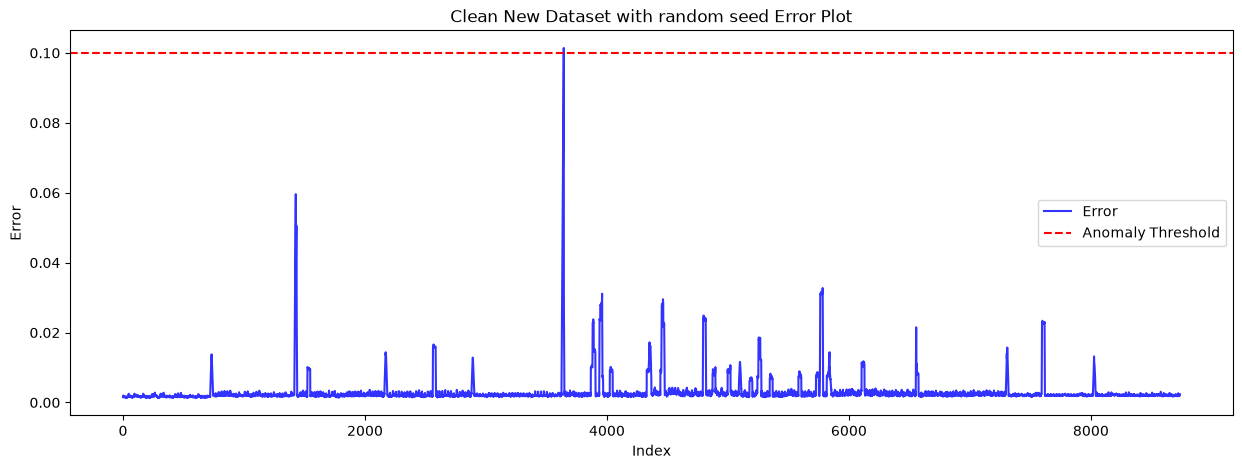

In [ ]:
plot_graph(testF(model,X_test),.1,"Clean New Dataset with random seed Error Plot")

In [ ]:
# next(iter(X_test)).shape

AttributeError: 'list' object has no attribute 'shape'

## For Injected Hour anamolies

In [ ]:
Val_A=Val.copy()
l=min(len(Test),len(Val_A))
idxs=[random.randint(0,l-1) for _ in range(10)]
for idx in idxs:
    Val_A[idx]=Test[idx]
X_val_A = PackintoWindows(Val_A, n=24)
X_test_H=torch.utils.data.TensorDataset(X_val_A,X_val_A)
X_test_H=torch.utils.data.DataLoader(X_test_H,batch_size=batch_size,shuffle=False)

In [ ]:
label=[0]*len(X_test_H.dataset)
print(len(label))
for idx in idxs:
    label[idx]=1
label=np.array(label)
Counter(label)

8736


Counter({np.int64(0): 8726, np.int64(1): 10})

Total sequences : 8736
Anomalies caughts: 227


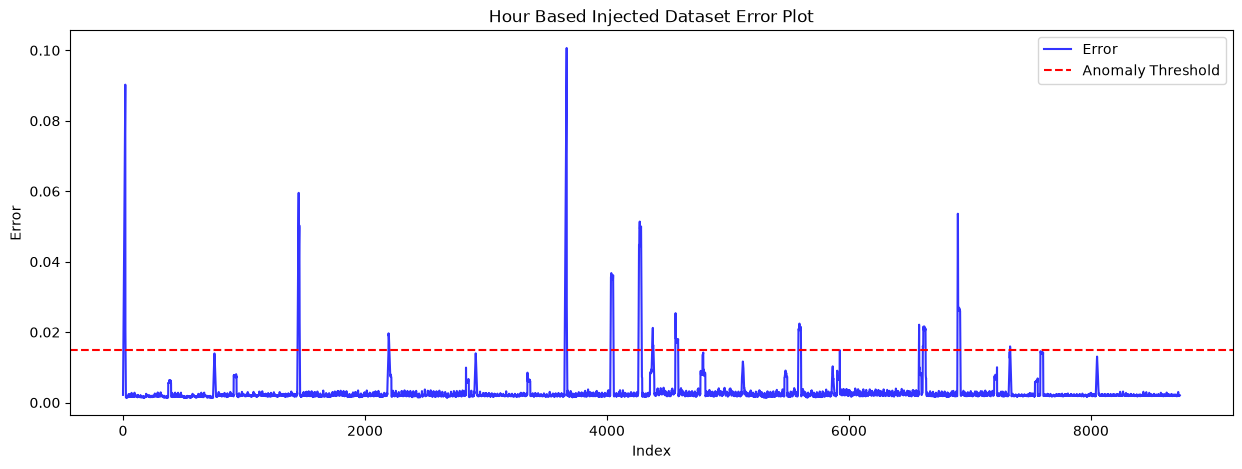

In [ ]:
seq=testF(model,X_test_H)
plot_graph(seq,.015,"Hour Based Injected Dataset Error Plot")

In [30]:
model.eval()
dum=torch.randn(64,24,22)
onnxM=torch.onnx.export(model,(dum,),dynamo=True)
onnxM.save("onnxModel.onnx")

[torch.onnx] Obtain model graph for `lsmtAE([...]` with `torch.export.export(..., strict=False)`...


/usr/lib/python3.12/contextlib.py:144: UserWarning: The tensor attributes self.decoder.l2._flat_weights[0], self.decoder.l2._flat_weights[1], self.decoder.l2._flat_weights[2], self.decoder.l2._flat_weights[3], self.encoder.l2._flat_weights[0], self.encoder.l2._flat_weights[1], self.encoder.l2._flat_weights[2], self.encoder.l2._flat_weights[3], self.encoder.l1._flat_weights[0], self.encoder.l1._flat_weights[1], self.encoder.l1._flat_weights[2], self.encoder.l1._flat_weights[3], self.decoder.l1._flat_weights[0], self.decoder.l1._flat_weights[1], self.decoder.l1._flat_weights[2], self.decoder.l1._flat_weights[3] were assigned during export. Such attributes must be registered as buffers using the `register_buffer` API (https://pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.register_buffer).
  next(self.gen)


[torch.onnx] Obtain model graph for `lsmtAE([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
